## import the segment wise absolute correlation matrices

In [8]:
from pathlib import Path
import pandas as pd

abs_segment_base = Path('../correlation_matrices_segment_wise_absolute')
matrix_files = list(abs_segment_base.rglob('*.csv'))

if matrix_files:
    sample = pd.read_csv(matrix_files[0], index_col=0)
    print(f"Found {len(matrix_files)} absolute matrices. Sample shape: {sample.shape}")


Found 2632 absolute matrices. Sample shape: (19, 19)


## filter the subjects for our study

In [9]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations

# Filter subjects
subject_ids = [64, 65, 69, 70, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 89, 90, 94, 96, 103]
formatted_subjects = [f"sub-NORB{sid:05d}" for sid in subject_ids]

# Extract first 12 segments for session 1
n_segments = 12
subject_matrices = {}

for subj in formatted_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    if not subj_dir.exists():
        print(f"Warning: directory not found for {subj}")
        continue
        
    csv_files = sorted(subj_dir.glob('*.csv'))
    if len(csv_files) < n_segments:
        print(f"Warning: {subj} has less than {n_segments} segments")
        
    matrices = []
    for csv_file in csv_files[:n_segments]:
        df = pd.read_csv(csv_file, index_col=0)
        matrices.append(df.values)
        
    if matrices:
        avg_matrix = np.mean(matrices, axis=0)
        subject_matrices[subj] = pd.DataFrame(avg_matrix, index=df.index, columns=df.columns)
        
print(f"Processed {len(subject_matrices)} subjects")


Processed 20 subjects


## calculate node strength for all nodes of the filtered subjects

In [10]:
import networkx as nx
import numpy as np

subject_node_strength = {}

for subj, df in subject_matrices.items():
    # Create graph from adjacency matrix
    G = nx.from_pandas_adjacency(df)
    
    # Calculate node strength centrality
    ns = {node: G.degree(node, weight='weight') for node in G.nodes()}
    
    # Store the result
    subject_node_strength[subj] = ns

print(f"Calculated node strength for {len(subject_node_strength)} subjects")

Calculated node strength for 20 subjects


## plot node strength heatmap

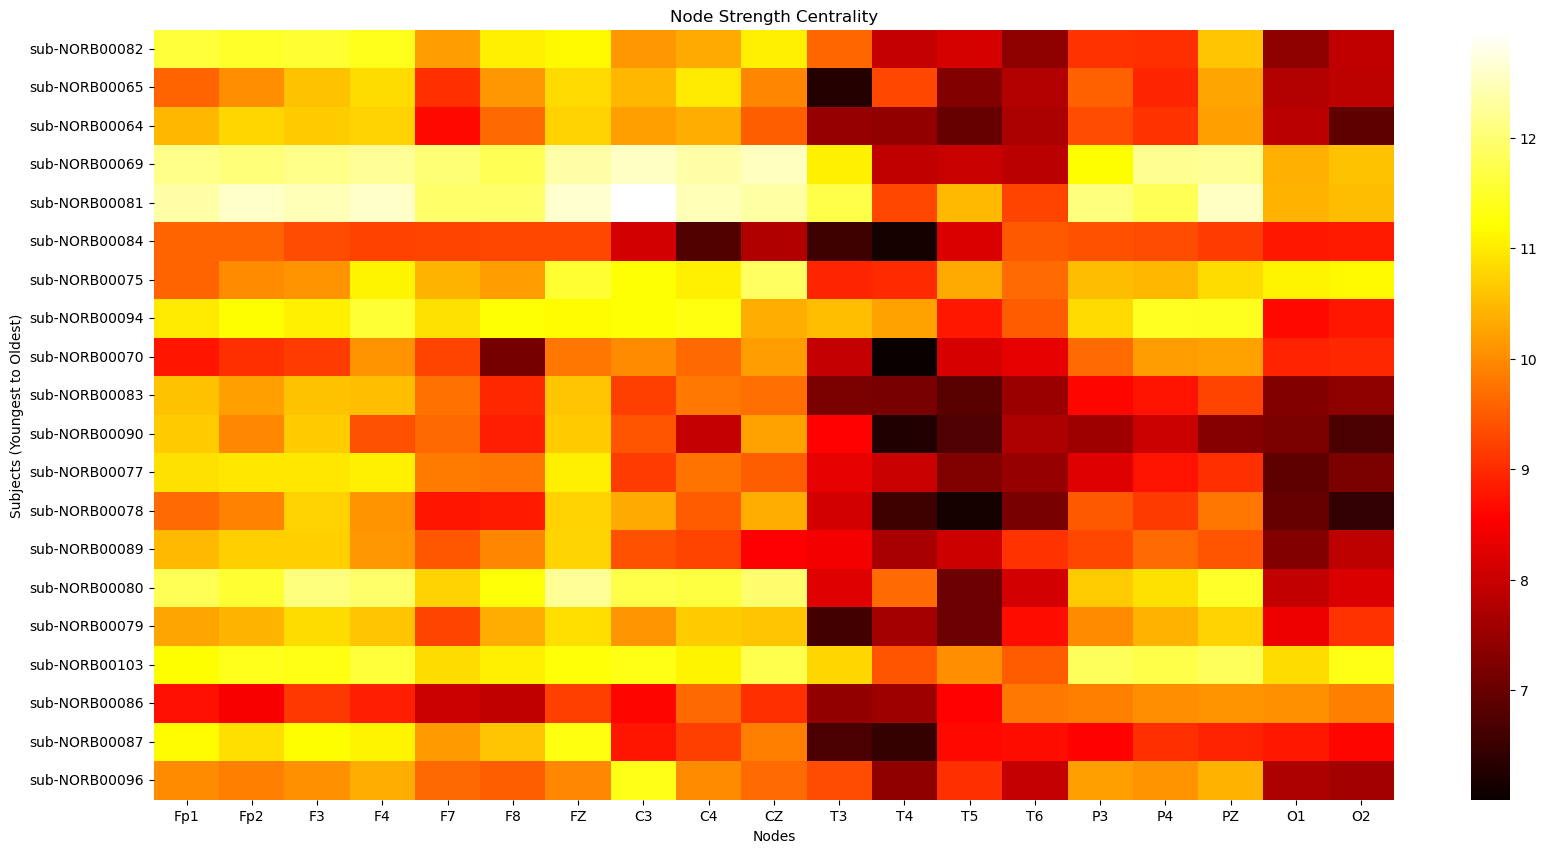

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

node_labels = ['Fp1', 'Fp2', 'F3', 'F4', 'F7', 'F8', 'FZ', 'C3', 'C4', 'CZ', 'T3', 'T4', 'T5', 'T6', 'P3', 'P4', 'PZ', 'O1', 'O2']

# Load ages and sort subjects increasing (oldest top, youngest bottom)
ages_df = pd.read_csv('../age_acq_time_sorted.csv')
target_labels = [f"{subj}_ses-1" for subj in formatted_subjects]
ages_filtered = ages_df[ages_df['label'].isin(target_labels)].copy()
# User requested increasing order of their age
ages_filtered = ages_filtered.sort_values('age_acq_time', ascending=False)

sorted_subject_labels = ages_filtered['label'].tolist()
sorted_subjects = [label.split('_')[0] for label in sorted_subject_labels]

# Prepare data for heatmap
heatmap_data = []
valid_subjects = []

for subj in sorted_subjects:
    if subj in subject_node_strength:
        valid_subjects.append(subj)
        ns = subject_node_strength[subj]
        row_data = []
        for n in node_labels:
            val = ns.get(n, 0)
            row_data.append(val)
        heatmap_data.append(row_data)

heatmap_data = np.array(heatmap_data)

# Plot heatmap
plt.figure(figsize=(20, 10))
sns.heatmap(heatmap_data, cmap='hot', xticklabels=node_labels, yticklabels=valid_subjects)
plt.title('Node Strength Centrality')
plt.xlabel('Nodes')
plt.ylabel('Subjects (Youngest to Oldest)')
plt.show()


## calculate weighted jaccard index for node strength

this cell calculates the weighted jaccard index (min/max) per segment for all 19 nodes between every pair of subjects.
for each node, the jaccard index is computed for each of the 12 segments by dividing the minimum strength value by the maximum value. these 12 values are then averaged to give exactly 19 jaccard indices per subject pair (one for each node). finally, the average of these 19 indices is also computed.

In [12]:
import networkx as nx
import numpy as np
import pandas as pd
from itertools import combinations
from pathlib import Path

# 1. Calculate node strength for each segment individually for all filtered subjects
subject_segment_ns = {}

for subj in formatted_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    if not subj_dir.exists():
        continue

    csv_files = sorted(subj_dir.glob('*.csv'))
    subject_segment_ns[subj] = []

    for csv_file in csv_files[:n_segments]:
        df = pd.read_csv(csv_file, index_col=0)
        G = nx.from_pandas_adjacency(df)

    # Calculate node strength centrality
        ns = {node: G.degree(node, weight='weight') for node in G.nodes()}
        subject_segment_ns[subj].append(ns)

print(f"Calculated individual segment node strength for {len(subject_segment_ns)} subjects.")

# 2. Calculate Weighted Jaccard Index for all pairs of subjects
sample_subj = formatted_subjects[0]
nodes_list = list(subject_segment_ns[sample_subj][0].keys())

pair_jaccard_avg = {}
pair_jaccard_all_nodes = {}

# Iterate over all 20C2 pairs
for subj_A, subj_B in combinations(formatted_subjects, 2):
    node_jaccards = []

    for n in nodes_list:
        segment_jaccards = []

        for s in range(n_segments):
            if s < len(subject_segment_ns[subj_A]) and s < len(subject_segment_ns[subj_B]):
                val_A = subject_segment_ns[subj_A][s].get(n, 0)
                val_B = subject_segment_ns[subj_B][s].get(n, 0)

                if max(val_A, val_B) > 0:
                    jaccard_s = min(val_A, val_B) / max(val_A, val_B)
                else:
                    jaccard_s = 0
                segment_jaccards.append(jaccard_s)

        # Average the segment Jaccards for this node
        node_jaccard_avg = np.mean(segment_jaccards) if segment_jaccards else 0
        node_jaccards.append(node_jaccard_avg)

    pair_jaccard_all_nodes[(subj_A, subj_B)] = node_jaccards
    pair_jaccard_avg[(subj_A, subj_B)] = np.mean(node_jaccards)

print(f"Calculated average Jaccard index for {len(pair_jaccard_avg)} subject pairs.")

Calculated individual segment node strength for 20 subjects.
Calculated average Jaccard index for 190 subject pairs.


## plot jaccard index heatmap for subject pairs

plots the jaccard index for all 19 nodes across all 190 subject pairs. the y-axis displays subject pairs sorted by the difference in their ages, with the smallest age difference at the bottom.

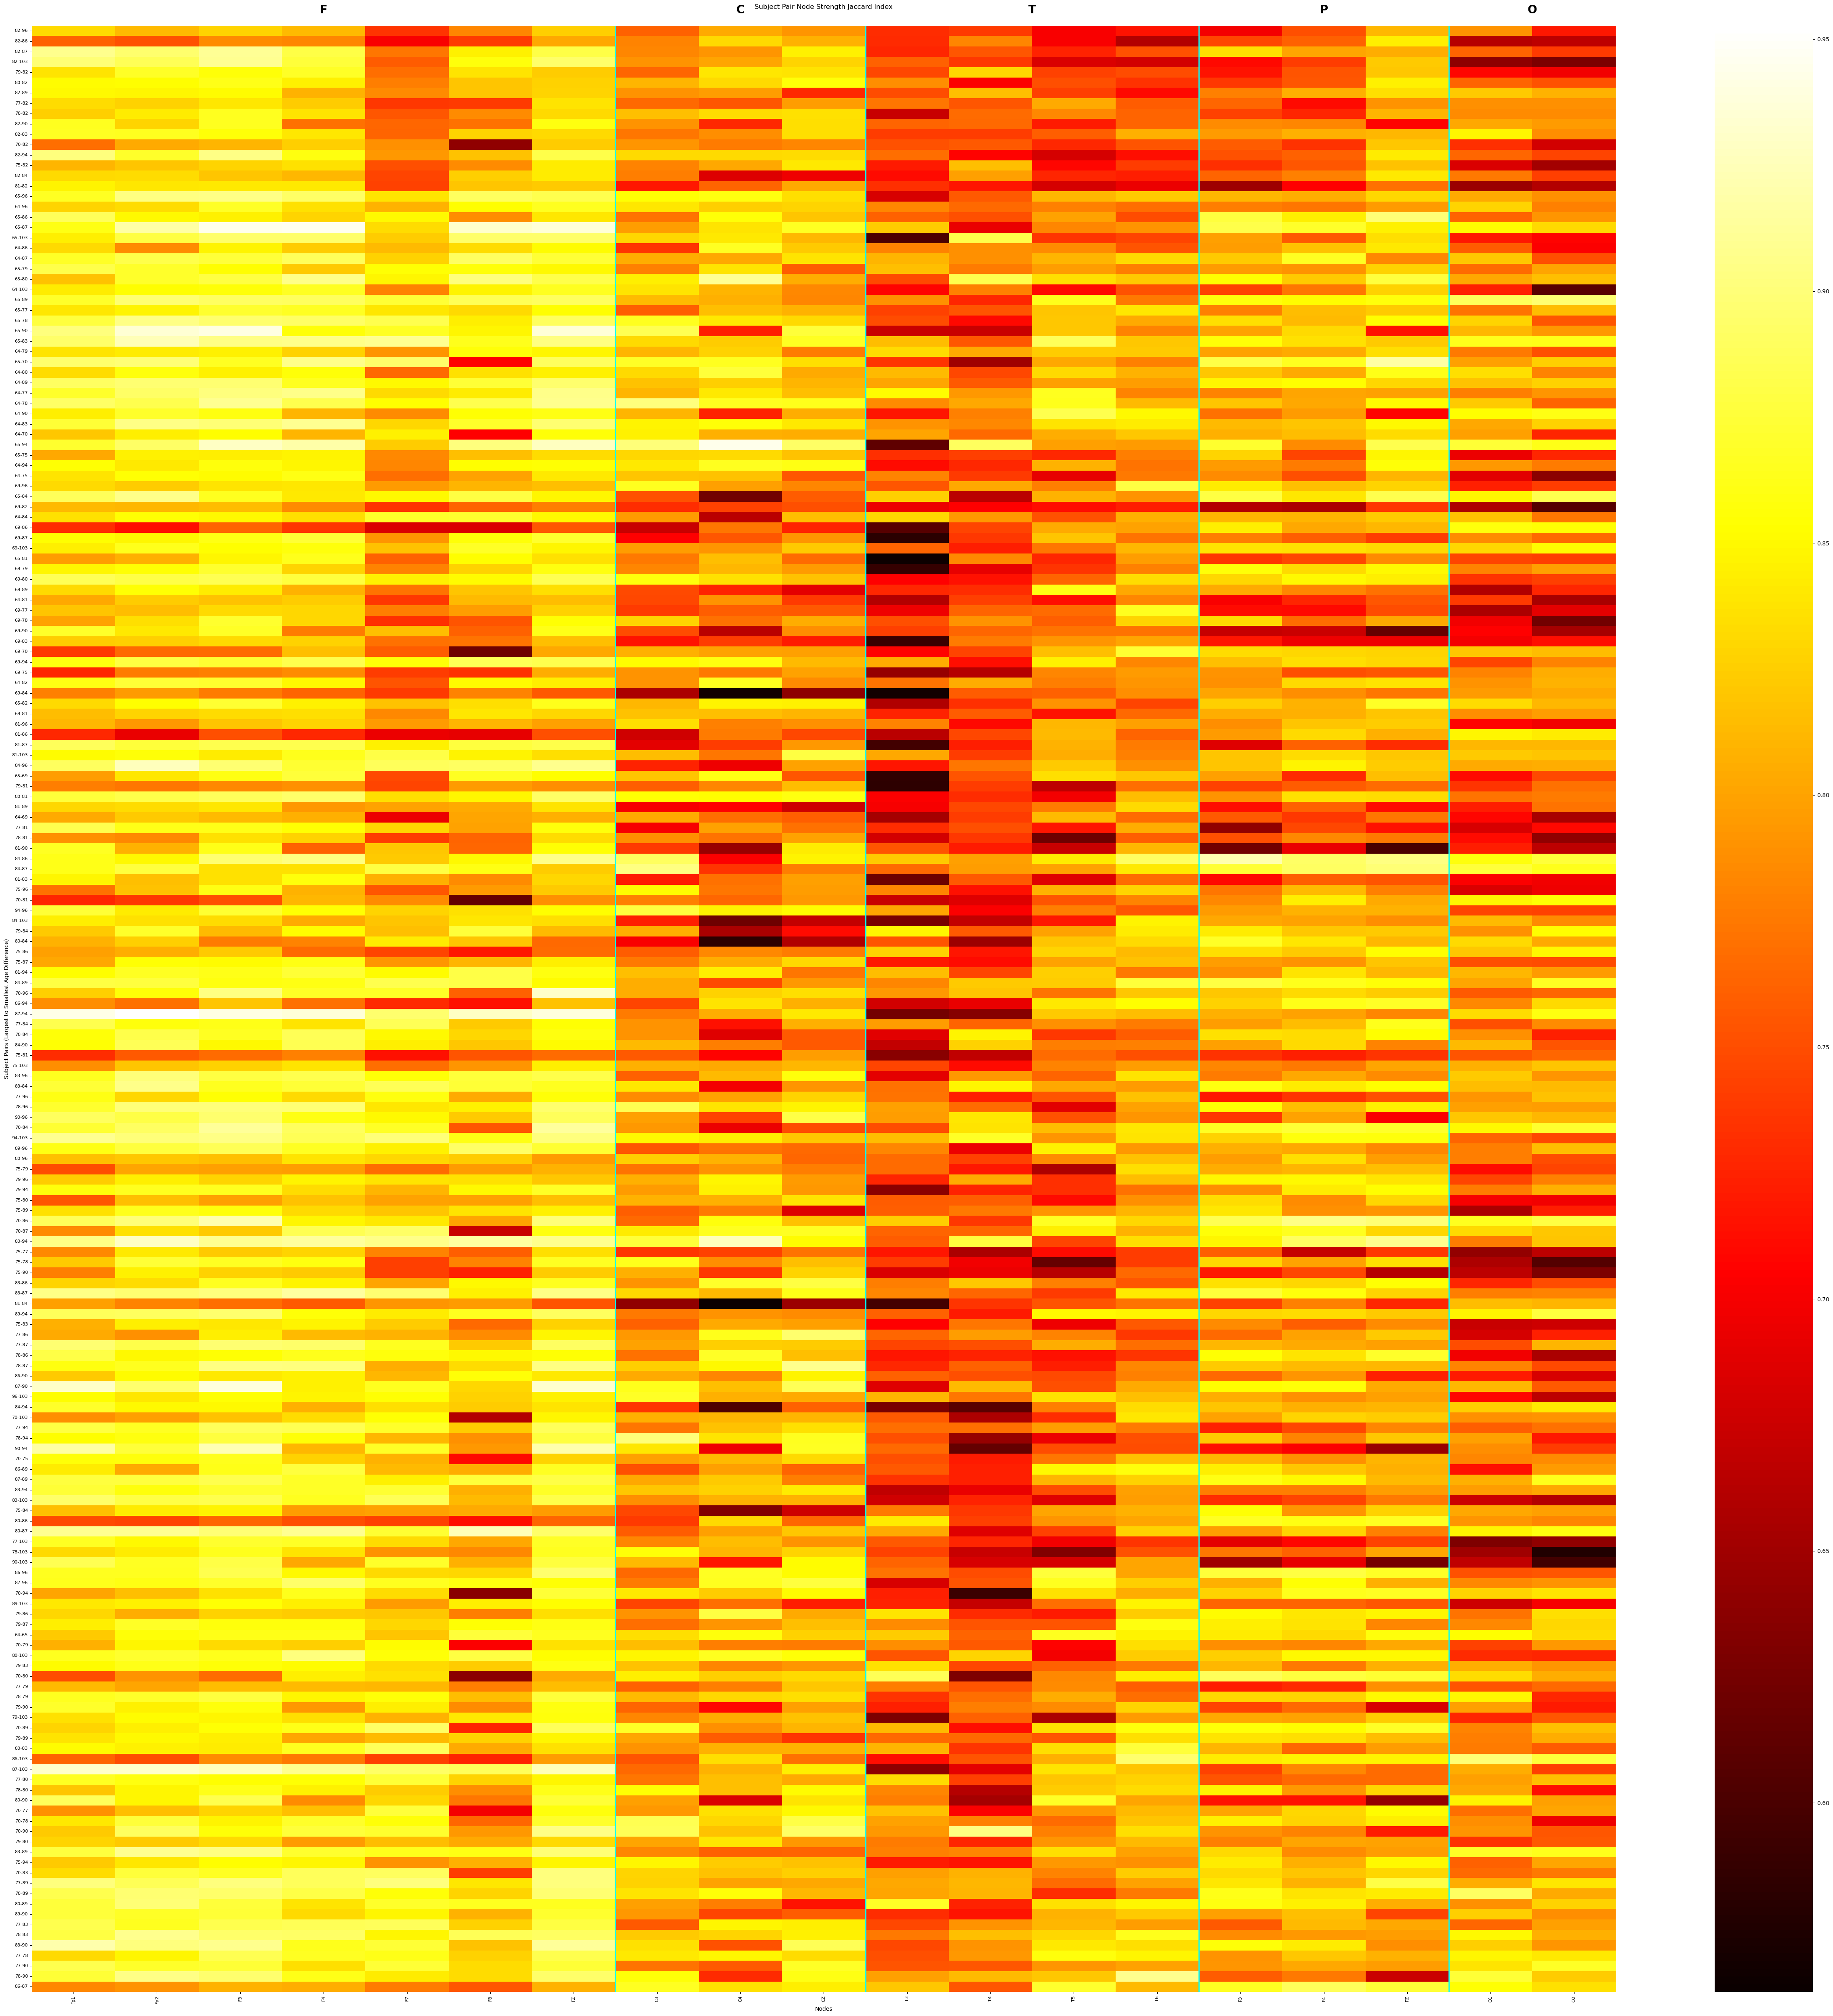

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get the age data
ages_df = pd.read_csv('../age_acq_time_sorted.csv')
target_labels = [f"{subj}_ses-1" for subj in formatted_subjects]
ages_filtered = ages_df[ages_df['label'].isin(target_labels)]

age_dict = {}
for idx, row in ages_filtered.iterrows():
    subj = row['label'].split('_')[0]
    age_dict[subj] = row['age_acq_time']

# Calculate age difference for each pair
pair_age_diff = {}
for pair in pair_jaccard_all_nodes.keys():
    subj_A, subj_B = pair
    diff = abs(age_dict[subj_A] - age_dict[subj_B])
    pair_age_diff[pair] = diff

# Sort pairs by age difference descending (largest diff at top, smallest diff at bottom)
sorted_pairs = sorted(pair_age_diff.keys(), key=lambda x: pair_age_diff[x], reverse=True)

# Map original nodes_list to node_labels order
node_to_index = {n: i for i, n in enumerate(nodes_list)}

heatmap_data = []
yticklabels = []

for pair in sorted_pairs:
    p0 = str(int(pair[0].replace('sub-NORB', '')))
    p1 = str(int(pair[1].replace('sub-NORB', '')))
    yticklabels.append(f"{p0}-{p1}")
    row_data = []
    for n in node_labels:
        idx = node_to_index.get(n, -1)
        val = pair_jaccard_all_nodes[pair][idx] if idx != -1 else 0
        row_data.append(val)
    heatmap_data.append(row_data)

heatmap_data = np.array(heatmap_data)

# Plot heatmap
plt.figure(figsize=(50, 50))
sns.heatmap(heatmap_data, cmap='hot', xticklabels=node_labels, yticklabels=yticklabels)

# add label above each lobe
import matplotlib.transforms as transforms

ax = plt.gca()
trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)

# Define each lobe label and its ending column index based on node_labels
# F: 7 nodes (0-6), C: 3 nodes (7-9), T: 4 nodes (10-13), P: 3 nodes (14-16), O: 2 nodes (17-18)
lobes = [
    ('F', 7),
    ('C', 10),
    ('T', 14),
    ('P', 17),
    ('O', 19)
]

start_idx = 0
for label, end_idx in lobes:
    # Draw vertical cyan dashed boundary line between lobes (except at the very right edge)
    if end_idx < 19:
        ax.axvline(x=end_idx, color='cyan', linewidth=2)
        
    # Add lobe label centered above its respective section at the top of the plot
    mid_x = (start_idx + end_idx) / 2.0
    ax.text(mid_x, 1.005, label, transform=trans, ha='center', va='bottom', fontsize=20, fontweight='bold')
    
    start_idx = end_idx


plt.title('Subject Pair Node Strength Jaccard Index', pad=30)
plt.xlabel('Nodes')
plt.ylabel('Subject Pairs (Largest to Smallest Age Difference)')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


## Region-wise Statistical Summary of Node Strength Jaccard Index

This cell calculates and displays a grouped bar plot showing the percentage of Node Strength Jaccard index values exceeding **0.75** and **0.90** for each distinct brain region (**F**, **C**, **T**, **P**, and **O**).

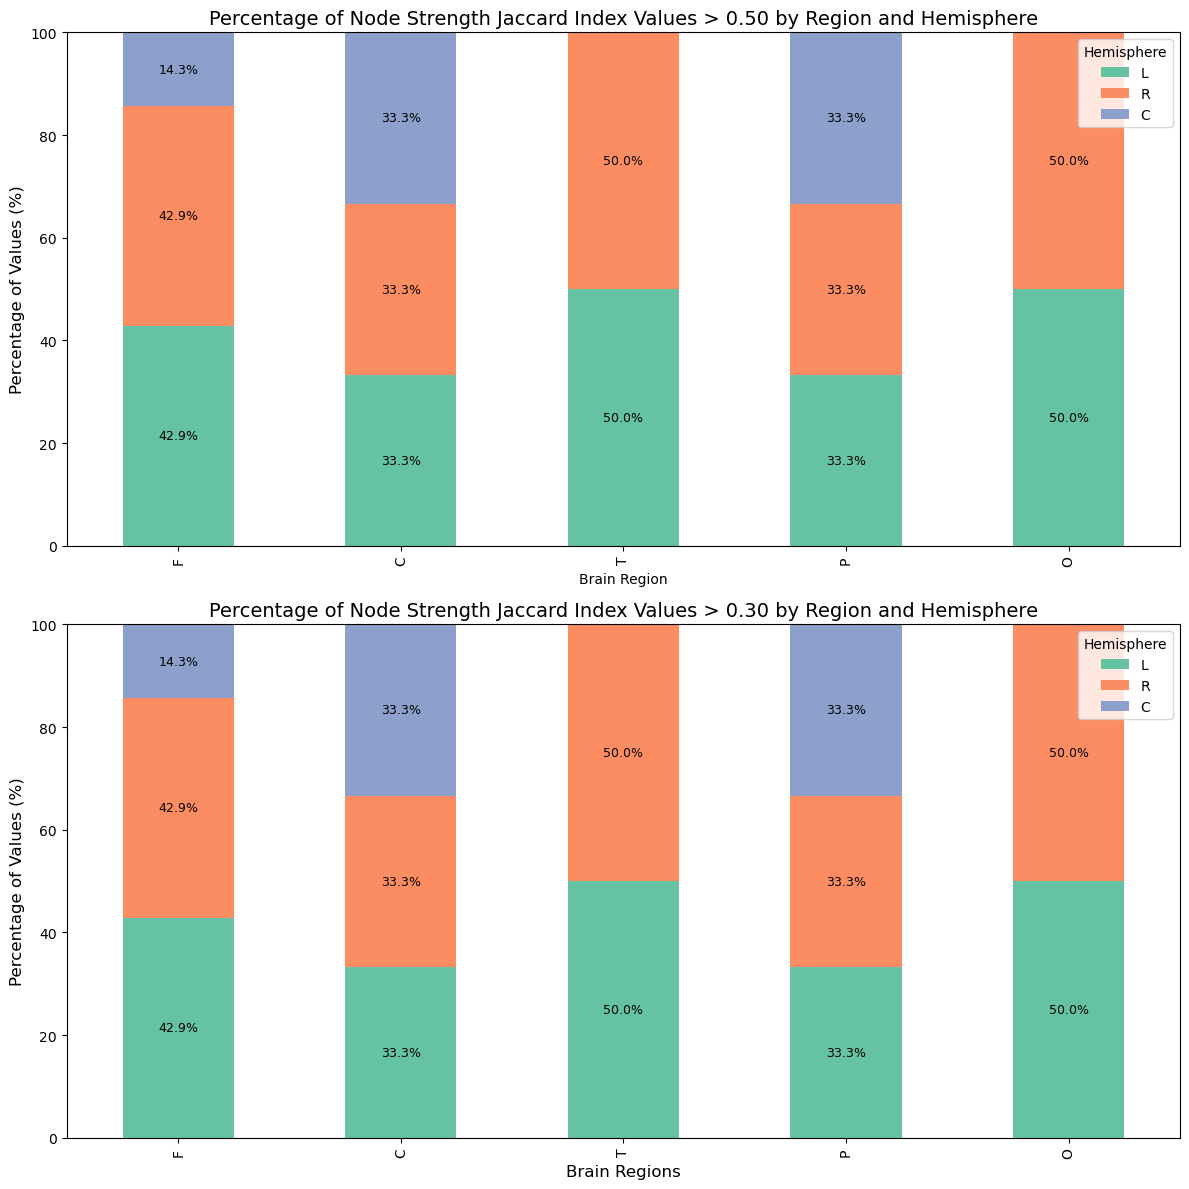

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Load Hemisphere Labels ---
labels_df = pd.read_csv('../electrode_labels.csv')
hemi_map = dict(zip(labels_df['channel'], labels_df['label']))

def get_hemi(node):
    return hemi_map.get(node, 'C')

# --- 2. Map every node to Region and Hemisphere ---
region_groups = ['F', 'C', 'T', 'P', 'O']
hemi_groups = ['L', 'R', 'C']

stats_data = []

for cat in region_groups:
    # Find all nodes belonging to this Region (F, C, T, P, O)
    node_indices = [idx for idx, n in enumerate(node_labels) if n[0].upper() == cat]
    
    total_vals_in_region = len(node_indices) * heatmap_data.shape[0]
    
    for hemi in hemi_groups:
        hemi_indices = [idx for idx in node_indices if get_hemi(node_labels[idx]) == hemi]
        
        if hemi_indices and total_vals_in_region > 0:
            vals = heatmap_data[:, hemi_indices].flatten()
            pct_75 = (np.sum(vals > 0.50) / total_vals_in_region) * 100.0
            pct_90 = (np.sum(vals > 0.30) / total_vals_in_region) * 100.0
        else:
            pct_75, pct_90 = 0.0, 0.0
            
        stats_data.append({'Brain Region': cat, 'Threshold': '> 0.50', 'Hemi': hemi, 'Percentage': pct_75})
        stats_data.append({'Brain Region': cat, 'Threshold': '> 0.30', 'Hemi': hemi, 'Percentage': pct_90})

df_stats = pd.DataFrame(stats_data)

# --- 4. Plot the Stacked Bar Charts ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 12))

colors = sns.color_palette("Set2", 3)

# Plot 1: > 0.50 Threshold
df_75 = df_stats[df_stats['Threshold'] == '> 0.50'].pivot(index='Brain Region', columns='Hemi', values='Percentage')
df_75 = df_75.reindex(index=region_groups, columns=hemi_groups)
df_75.plot(kind='bar', stacked=True, ax=ax1, color=colors)

ax1.set_title('Percentage of Node Strength Jaccard Index Values > 0.50 by Region and Hemisphere', fontsize=14)
ax1.set_ylabel('Percentage of Values (%)', fontsize=12)
ax1.set_ylim(0, 100)
ax1.legend(title='Hemisphere', loc='upper right')

# Plot 2: > 0.30 Threshold
df_90 = df_stats[df_stats['Threshold'] == '> 0.30'].pivot(index='Brain Region', columns='Hemi', values='Percentage')
df_90 = df_90.reindex(index=region_groups, columns=hemi_groups)
df_90.plot(kind='bar', stacked=True, ax=ax2, color=colors)

ax2.set_title('Percentage of Node Strength Jaccard Index Values > 0.30 by Region and Hemisphere', fontsize=14)
ax2.set_xlabel('Brain Regions', fontsize=12)
ax2.set_ylabel('Percentage of Values (%)', fontsize=12)
ax2.set_ylim(0, 100)
ax2.legend(title='Hemisphere', loc='upper right')

# Add percentage text labels directly on the stacked bar sections
for ax in [ax1, ax2]:
    for c in ax.containers:
        # Only annotate sections that are large enough to fit text
        ax.bar_label(c, fmt=lambda x: f'{x:.1f}%' if x > 2 else '', label_type='center', fontsize=9)

plt.tight_layout()
plt.show()
